# Laboratory 3 - Pruning

In Laboratory 2 we made `SmallCNN` smaller by using fewer bits per number. Today we use the other lever: **fewer numbers**. Pruning removes parameters from a trained network, either one by one or in whole groups.

**What you should already know:** Laboratories 1 and 2: the training loop, `SmallCNN` on CIFAR-10, the size estimates, and what PTQ and QAT are.

**What you will be able to do after this notebook:** prune a network with `torch.nn.utils.prune`, explain the difference between unstructured and structured pruning and what each of them does to memory and computation, physically remove channels from a convolutional network, run iterative pruning with fine-tuning, and combine pruning with quantization to find the best trade-offs between size and accuracy.

Plan:

0. Setup
1. Recap and the baseline
2. What pruning is: one mask by hand
3. Unstructured pruning: random against magnitude, convolutions against the linear layer, and what it does to memory
4. Structured pruning: a mask by hand, removing whole channels, and what that does to memory
5. Iterative pruning
6. Pruning and quantization together: a Pareto front
7. Exercises, questions, summary

**How to work.** Complete the cells marked `# TODO`. The text right above each cell tells you what is needed. You may use an LLM for the code, but after the class you will be asked about the theory and about your own results, without the notebook. Answer the **Question** boxes for yourself before you run the next cell.

## 0. Setup

Use the **same environment as in Laboratories 1 and 2**. Nothing new is installed.

```
conda activate embedded-ai          # conda
source .venv/bin/activate           # venv, Linux / macOS
.venv\Scripts\activate              # venv, Windows
```

Put the notebook in the same folder as Laboratory 2. The `data` folder and the checkpoint `smallcnn_fp_epoch10.pth` are then reused, and no training is needed at the start.

In [1]:
import io
import os
import time
import copy
import zipfile

import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.utils.prune as prune
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

print("torch version:", torch.__version__)
# device = "cuda" if torch.cuda.is_available() else "cpu"
device = "mps"
print("Using device:", device)

torch.manual_seed(0)

torch version: 2.13.0
Using device: mps


## 1. Recap and the baseline

The data, `evaluate` and `train` are unchanged. `SmallCNN` has one addition: the optional argument `channels` sets the number of channels of each block directly. With the default it is exactly the network from Laboratories 1 and 2. We will need the argument in Section 4.

In [2]:
data_dir = "data"
if not os.path.isdir(os.path.join(data_dir, "cifar-10-batches-py")):
    print("CIFAR-10 not found locally, downloading...")
    import gdown
    zip_path = "cifar10.zip"
    gdown.download(id="1b7UF-Wu6aiOUhy4W2Yl9_1cO4SSApAPn", output=zip_path, quiet=False)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(".")
    os.remove(zip_path)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])
train_set = datasets.CIFAR10("data", train=True, download=True, transform=transform)
test_set = datasets.CIFAR10("data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
test_loader = DataLoader(test_set, batch_size=1000)


def conv_block(in_channels, out_channels):
    return [
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.MaxPool2d(2),
    ]


class SmallCNN(nn.Module):
    def __init__(self, width=16, channels=None):
        super().__init__()
        c1, c2, c3 = channels if channels is not None else (width, 2 * width, 4 * width)
        self.features = nn.Sequential(
            *conv_block(3, c1),
            *conv_block(c1, c2),
            *conv_block(c2, c3),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(c3 * 4 * 4, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def evaluate(model, loader):
    model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            correct += (model(images).argmax(dim=1) == labels).sum().item()
    return correct / len(loader.dataset)


def train(model, epochs, lr=1e-3):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train()
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            loss = F.cross_entropy(model(images), labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        print(f"epoch {epoch + 1}/{epochs}  last batch loss: {loss.item():.3f}  "
              f"test accuracy: {evaluate(model, test_loader):.3f}")


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

The baseline is the 10-epoch float model from Laboratory 2. If the checkpoint is not in the folder, the cell trains it again.

Two helpers are defined here and used everywhere below: `conv_layers(model)` returns the three convolutions, and `prunable_layers(model)` returns the convolutions and the linear layer.

In [3]:
CKPT = "smallcnn_fp_epoch10.pth"

if not os.path.exists(CKPT):
    torch.manual_seed(1)
    model = SmallCNN(width=16)
    train(model, epochs=10)
    torch.save(model.state_dict(), CKPT)


def load_fp():
    # Returns a fresh copy of the trained float model
    model = SmallCNN(width=16)
    model.load_state_dict(torch.load(CKPT, map_location=device))
    return model.to(device).eval()


def conv_layers(model):
    return [m for m in model.modules() if isinstance(m, nn.Conv2d)]


def prunable_layers(model):
    return [m for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]


base_acc = evaluate(load_fp(), test_loader)
print(f"baseline: {count_parameters(load_fp())} parameters, accuracy {base_acc:.4f}")

baseline: 34058 parameters, accuracy 0.7513


## 2. What pruning is

Trained networks have more parameters than they need. Many weights are close to zero and contribute almost nothing to the output. **Pruning** removes parameters from a trained network: single connections, or whole neurons and channels.

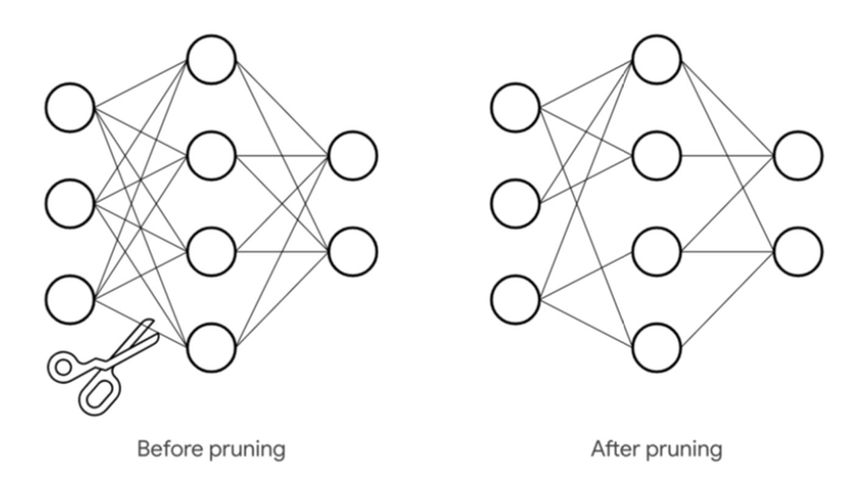

Every pruning method answers two questions:

- **What is removed?** Single weights anywhere in the network (*unstructured* pruning) or whole groups such as filters and channels (*structured* pruning).
- **How is it chosen?** By a *criterion* that estimates how important a weight is. The simplest one is the magnitude: a weight close to zero changes the output little, so it is the first candidate.

The fraction of weights that are zero is called the **sparsity**.

In practice "removing" a weight means setting it to zero. This is done with a **mask**: a tensor of the same shape as the weights that holds 1 for every weight that is kept and 0 for every weight that is pruned. The pruned weights are `weight * mask`.

Before using a library, build one mask by hand, for the second convolution, and prune the 50% of its weights with the smallest absolute value. Two functions that you may not know:

- `tensor.detach()` returns the values of a tensor without the gradient bookkeeping,
- `tensor.flatten().kthvalue(k).values` returns the `k`-th smallest element of a tensor.

threshold: 0.0550   sparsity of the layer: 0.500


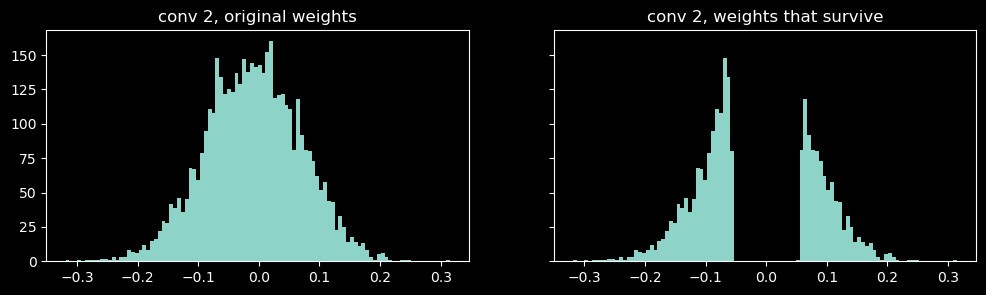

baseline accuracy: 0.7513
accuracy with half of the weights of conv 2 removed: 0.7274


In [4]:
model = load_fp()
w = model.features[4].weight.detach()        # second convolution, shape [32, 16, 3, 3]
amount = 0.5

# TODO (student): 1. k:         how many weights have to be pruned
#                 2. threshold: the k-th smallest absolute value among the weights
#                 3. mask:      1.0 where the absolute value is above the threshold, 0.0 elsewhere
#                 4. w_pruned:  the weights with the mask applied
k = int(amount * w.numel())
threshold = w.abs().flatten().kthvalue(k).values
mask = (w.abs() > threshold).float()
w_pruned = w * mask

sparsity = (w_pruned == 0).float().mean().item()
print(f"threshold: {threshold.item():.4f}   sparsity of the layer: {sparsity:.3f}")
assert abs(sparsity - amount) < 0.01

fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
axes[0].hist(w.flatten().tolist(), bins=100)
axes[0].set_title("conv 2, original weights")
axes[1].hist(w_pruned[mask == 1].tolist(), bins=100)
axes[1].set_title("conv 2, weights that survive")
plt.show()

with torch.no_grad():
    model.features[4].weight.copy_(w_pruned)
print(f"baseline accuracy: {base_acc:.4f}")
conv2_unstructured_acc = evaluate(model, test_loader)
print(f"accuracy with half of the weights of conv 2 removed: {conv2_unstructured_acc:.4f}")

The middle of the histogram is gone: the mask removed exactly the weights around zero and kept the tails.

> **Question.** Half of the weights of one layer are gone and nothing was retrained. Is the loss of accuracy larger or smaller than you expected? What does that say about the weights that were removed?

## 3. Unstructured pruning

### 3.1 The same thing with `torch.nn.utils.prune`

From here on we use the pruning tools that come with PyTorch, imported as `prune`. They build the same kind of mask for you. The call

```
prune.l1_unstructured(layer, name="weight", amount=0.5)
```

prunes the 50% of the entries of `layer.weight` with the smallest absolute value (the L1 norm of a single number is its absolute value). The function changes the layer in place:

- the original weights move to a new parameter, `weight_orig`,
- the mask is stored as a buffer, `weight_mask`,
- `layer.weight` becomes a computed attribute, `weight_orig * weight_mask`, recalculated before every forward pass.

Nothing is deleted. The original values are still there, they are only hidden behind the mask.

In [9]:
model = load_fp()
conv2 = model.features[4]
print("before:", [name for name, _ in conv2.named_parameters()], [name for name, _ in conv2.named_buffers()])

# TODO (student): prune 50% of the weights of conv2 with prune.l1_unstructured
prune.l1_unstructured(conv2, name="weight", amount=0.5)

print("after: ", [name for name, _ in conv2.named_parameters()], [name for name, _ in conv2.named_buffers()])
print("weight == weight_orig * weight_mask:", torch.equal(conv2.weight, conv2.weight_orig * conv2.weight_mask))
print("same mask as the one you built by hand:", torch.equal(conv2.weight_mask, mask))

before: ['weight', 'bias'] []
after:  ['bias', 'weight_orig'] ['weight_mask']
weight == weight_orig * weight_mask: True
same mask as the one you built by hand: True


One practical warning. A pruned layer cannot be copied with `copy.deepcopy` once it has been used in a forward pass, because `weight` is then a computed tensor. Whenever we need a fresh model we therefore call `load_fp()` and prune again.

### 3.2 Random against magnitude

Is the choice of weights important, or is any 50% as good as another? `prune.random_unstructured` has the same arguments as `prune.l1_unstructured` and picks the weights at random.

First write `sparsity`, then prune every prunable layer of a fresh model with both methods, for several amounts.

You can use function `prunable_layers()` defined above.

> **Question (answer before running).** Nothing is retrained here. How much of the network do you expect to be able to remove with each method before the accuracy collapses?

amount                random    L1 (magnitude)
0.1                   0.4864            0.7454
0.25                  0.1798            0.6590
0.5                   0.1191            0.4665
0.75                  0.1000            0.1314
0.9                   0.1000            0.1196


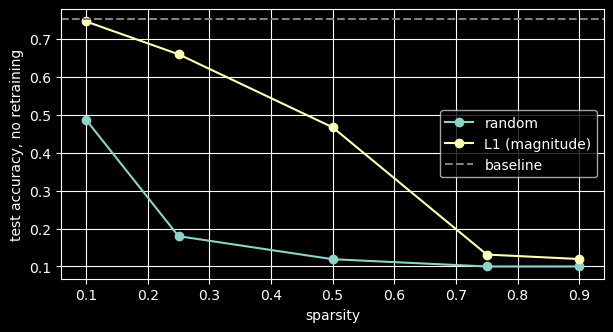

In [10]:
def sparsity(model):
    # The fraction of zero weights among the weights of all prunable layers
    # TODO (student)
    zeros = sum((m.weight == 0).sum().item() for m in prunable_layers(model))
    total = sum(m.weight.numel() for m in prunable_layers(model))
    return zeros / total


AMOUNTS = [0.1, 0.25, 0.5, 0.75, 0.9]
methods = {"random": prune.random_unstructured, "L1 (magnitude)": prune.l1_unstructured}
one_shot_acc = {name: [] for name in methods}

torch.manual_seed(0)
print(f"{'amount':<10}" + "".join(f"{name:>18}" for name in methods))
for amount in AMOUNTS:
    for name, method in methods.items():
        model = load_fp()
        for layer in prunable_layers(model):
            # TODO (student): prune every prunable layer of the model by `amount` with `method`
            method(layer, name="weight", amount=amount)
        assert abs(sparsity(model) - amount) < 0.01
        one_shot_acc[name].append(evaluate(model, test_loader))
    print(f"{amount:<10}" + "".join(f"{one_shot_acc[name][-1]:>18.4f}" for name in methods))

plt.figure(figsize=(7, 3.5))
for name in methods:
    plt.plot(AMOUNTS, one_shot_acc[name], "o-", label=name)
plt.axhline(base_acc, color="gray", linestyle="--", label="baseline")
plt.xlabel("sparsity")
plt.ylabel("test accuracy, no retraining")
plt.legend()
plt.grid()
plt.show()

Which weights are removed matters a great deal. Random pruning destroys the network almost immediately, while pruning by magnitude degrades it gradually.

Even magnitude pruning costs accuracy, because the remaining weights were trained to work together with the ones that are now gone. The remedy is **fine-tuning**: train the pruned network a little longer, so that the surviving weights can compensate.

Fine-tuning works with the mask in place. The optimizer updates `weight_orig`, the mask is applied in every forward pass, and the pruned weights stay at zero. Take the model with 50% magnitude pruning and fine-tune it for one epoch.

In [12]:
model_l1 = load_fp()
for layer in prunable_layers(model_l1):
    prune.l1_unstructured(layer, name="weight", amount=0.5)
print(f"before fine-tuning: sparsity {sparsity(model_l1):.3f}, accuracy {evaluate(model_l1, test_loader):.4f}")

# TODO (student): fine-tune model_l1 for one epoch with the plain train function
train(model_l1, epochs=1)

print(f"after fine-tuning:  sparsity {sparsity(model_l1):.3f}, accuracy {evaluate(model_l1, test_loader):.4f}")
print(f"baseline:           {base_acc:.4f}")

before fine-tuning: sparsity 0.500, accuracy 0.4665
epoch 1/1  last batch loss: 0.478  test accuracy: 0.746
after fine-tuning:  sparsity 0.500, accuracy 0.7459
baseline:           0.7513


The sparsity did not change during training, and the accuracy came back. Half of the weights of this network were not needed.

### 3.3 Convolutions and the linear layer

So far every layer lost the same fraction of its weights. The layers are not alike, though. `SmallCNN` has two kinds of them: three convolutions, and one linear layer at the end, which stands for the fully connected (MLP) part of larger networks.

The two kinds use their weights differently. A filter of a convolution is applied at **every position** of the feature map, so each of its weights takes part in many multiplications for one image. A weight of a linear layer connects one input to one output and is used **once**.

Two things follow from this, and the two cells below check both:

- **Memory and computation sit in different places.** A linear layer costs one multiplication per weight. A convolution costs one multiplication per weight *and per position*.
- **The layers should not be equally sensitive to pruning.** A missing weight of a convolution is missing at every position of the feature map. A missing weight of the linear layer removes a single connection.

Complete `layer_costs`. One output value of a convolution is a sum over all input channels and all positions of the kernel, and there is one output value for every output channel at every position of the feature map.

In [14]:
def layer_costs(model):
    # For every layer with weights: its name, its number of weights and its multiplications for one image
    costs = []
    size = 32                               # height and width of the feature map, 32 for the input image
    for layer in model.features:
        if isinstance(layer, nn.Conv2d):
            k = layer.kernel_size[0]
            # TODO (student): the number of multiplications of this convolution for one image
            mults = size * size * layer.in_channels * layer.out_channels * k * k

            costs.append({"name": f"conv {len(costs) + 1}", "weights": layer.weight.numel(), "mults": mults})
        elif isinstance(layer, nn.MaxPool2d):
            size //= 2
    linear = model.classifier[1]
    costs.append({"name": "linear", "weights": linear.weight.numel(), "mults": linear.weight.numel()})
    return costs


costs = layer_costs(load_fp())
total_weights = sum(c["weights"] for c in costs)
total_mults = sum(c["mults"] for c in costs)
assert total_mults == 2_811_904

print(f"{'layer':<8}{'weights':>9}{'share':>8}{'multiplications':>17}{'share':>8}{'uses of one weight':>20}")
for c in costs:
    print(f"{c['name']:<8}{c['weights']:>9}{c['weights'] / total_weights:>8.1%}{c['mults']:>17}"
          f"{c['mults'] / total_mults:>8.1%}{c['mults'] // c['weights']:>20}")

layer     weights   share  multiplications   share  uses of one weight
conv 1        432    1.3%           442368   15.7%                1024
conv 2       4608   13.7%          1179648   42.0%                 256
conv 3      18432   54.7%          1179648   42.0%                  64
linear      10240   30.4%            10240    0.4%                   1


The linear layer holds almost a third of the weights and does well under 1% of the work. The convolutions are the opposite: the first one has about 1% of the weights and a sizeable part of the multiplications.

Now the second claim. Prune **one layer at a time** by magnitude, leave the others untouched, and measure the accuracy without any retraining. A scan like this is called a *sensitivity analysis*.

> **Question (answer before running).** Which layer do you expect to be the most sensitive, and which one the least?

pruned layer        25%      50%      75%      90%
conv 1           0.6636   0.4968   0.2391   0.2183
conv 2           0.7529   0.7274   0.5884   0.3974
conv 3           0.7498   0.7343   0.5555   0.2498
linear           0.7498   0.7337   0.6775   0.5687


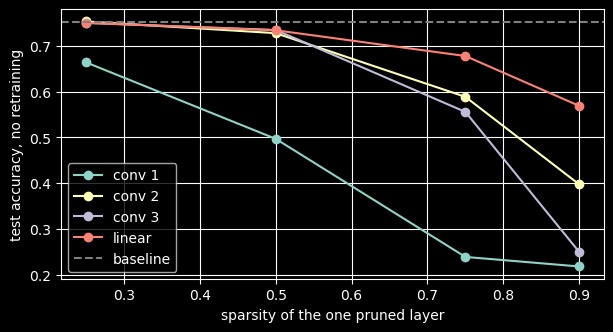

In [16]:
LAYER_AMOUNTS = [0.25, 0.5, 0.75, 0.9]
layer_acc = {c["name"]: [] for c in costs}

print(f"{'pruned layer':<14}" + "".join(f"{str(int(a * 100)) + '%':>9}" for a in LAYER_AMOUNTS))
for index, name in enumerate(layer_acc):
    for amount in LAYER_AMOUNTS:
        model = load_fp()
        # TODO (student): prune only layer number `index` of prunable_layers(model) by `amount`, by magnitude
        layer = prunable_layers(model)[index]
        prune.l1_unstructured(layer, name="weight", amount=amount)
        layer_acc[name].append(evaluate(model, test_loader))
    print(f"{name:<14}" + "".join(f"{acc:>9.4f}" for acc in layer_acc[name]))

plt.figure(figsize=(7, 3.5))
for name, accs in layer_acc.items():
    plt.plot(LAYER_AMOUNTS, accs, "o-", label=name)
plt.axhline(base_acc, color="gray", linestyle="--", label="baseline")
plt.xlabel("sparsity of the one pruned layer")
plt.ylabel("test accuracy, no retraining")
plt.legend()
plt.grid()
plt.show()

The order matches the expectation. The first convolution is by far the most sensitive: a quarter of its 432 weights already costs many points, and with three quarters gone the network barely works. The linear layer is the most tolerant: half of its weights can go for about a point, without any retraining. The other two convolutions lie in between.

The scan was done without retraining. The next cell checks whether the difference survives fine-tuning, on the two extreme layers: 90% of one layer is pruned and the network is trained for one more epoch. The table also shows what each of the two prunings would buy, in weights and in multiplications.

In [17]:
rows = []
for name in ["conv 1", "linear"]:
    index = list(layer_acc).index(name)
    # TODO (student): how many weights of this layer are removed at 90%, and how many multiplications
    #                 would disappear if the device could skip the zero weights? (see costs[index])
    # weights_removed = 
    # mults_removed = 
    weights_removed = 0.9 * costs[index]["weights"]
    mults_removed = 0.9 * costs[index]["mults"]

    print(f"--- 90% of {name} pruned ---")
    torch.manual_seed(7)
    model = load_fp()
    # TODO (student): prune 90% of this one layer by magnitude, then fine-tune the model for one epoch
    prune.l1_unstructured(prunable_layers(model)[index], name="weight", amount=0.9)
    train(model, epochs=1)

    rows.append((name, weights_removed, mults_removed, layer_acc[name][-1], evaluate(model, test_loader)))

print(f"\n{'pruned 90% of':<15}{'weights removed':>16}{'of all weights':>16}{'of all mult.':>14}{'no retraining':>15}{'fine-tuned':>12}")
for name, weights_removed, mults_removed, acc_before, acc_after in rows:
    print(f"{name:<15}{int(weights_removed):>16}{weights_removed / total_weights:>16.1%}{mults_removed / total_mults:>14.1%}"
          f"{acc_before:>15.4f}{acc_after:>12.4f}")
print(f"{'baseline':<15}{'':>46}{base_acc:>15.4f}")

--- 90% of conv 1 pruned ---
epoch 1/1  last batch loss: 0.847  test accuracy: 0.664
--- 90% of linear pruned ---
epoch 1/1  last batch loss: 0.721  test accuracy: 0.722

pruned 90% of   weights removed  of all weights  of all mult.  no retraining  fine-tuned
conv 1                      388            1.2%         14.2%         0.2183      0.6642
linear                     9216           27.3%          0.3%         0.5687      0.7217
baseline                                                              0.7513


After one epoch the network without 90% of its linear layer has recovered most of the loss and ends a couple of points below the baseline, although about a quarter of all the weights of the model are gone. The network without 90% of its first convolution stays clearly lower, and that pruning removed only about 1% of the weights.

What the two prunings would buy differs just as much. The linear layer is where the **memory** is: pruning it shrinks the model and leaves the amount of computation as it was. The first convolution is the opposite: almost no memory to gain, some computation, and the highest price in accuracy.

This is the usual pattern in convolutional networks. The fully connected part is the most redundant and tolerates the most pruning. The convolutions, the early ones above all, tolerate the least. Giving every layer the same amount, as we did in Section 3.2, is therefore not the best allocation (see exercise 1).

### 3.4 What did we save?

Back to the model of Section 3.2, in which half of the weights of every layer are zero. Is it half as large? Measure it. `saved_size_kb` writes the `state_dict` of a model into memory, exactly as `torch.save` would write it to a file, and returns the size.

`prune.remove(layer, "weight")` makes the pruning permanent: `weight_orig` and `weight_mask` disappear and `weight` becomes an ordinary parameter again, with the zeros written into it.

In [18]:
def saved_size_kb(model):
    buffer = io.BytesIO()
    torch.save(model.state_dict(), buffer)
    return buffer.getbuffer().nbytes / 1024


dense = load_fp()
print(f"{'model':<34}{'parameters':>12}{'saved [KB]':>12}{'sparsity':>10}")
print(f"{'dense':<34}{count_parameters(dense):>12}{saved_size_kb(dense):>12.1f}{sparsity(dense):>10.2f}")
print(f"{'pruned 50%, with masks':<34}{count_parameters(model_l1):>12}{saved_size_kb(model_l1):>12.1f}{sparsity(model_l1):>10.2f}")

# TODO (student): make the pruning of every prunable layer of model_l1 permanent
for layer in prunable_layers(model_l1):
    prune.remove(layer, "weight")



print(f"{'pruned 50%, permanent':<34}{count_parameters(model_l1):>12}{saved_size_kb(model_l1):>12.1f}{sparsity(model_l1):>10.2f}")

model                               parameters  saved [KB]  sparsity
dense                                    34058       141.2      0.00
pruned 50%, with masks                   34058       274.0      0.50
pruned 50%, permanent                    34058       141.2      0.50


With the masks the saved model is almost twice as large, because every weight now comes with a mask entry. After `prune.remove` it is exactly as large as the dense model. A zero is a float32 like any other number: it takes 4 bytes, and the device still multiplies by it.

This is the honest summary of unstructured pruning. It reaches a high sparsity with little loss of accuracy, but the weight tensors keep their shape, so an ordinary processor, a microcontroller or a standard accelerator gains nothing. Turning the zeros into savings needs a sparse storage format, in which every remaining weight is stored together with its position, and hardware or software that can skip the zeros.

> **Question.** The savings in the table of Section 3.3 were computed "if the device could skip the zero weights". What would a device have to do differently to compute a layer in that way?

## 4. Structured pruning

**Structured pruning** removes parameters in whole groups, chosen so that the weight tensor can be made smaller afterwards. In a convolution the natural group is a **filter**: one output channel with all of its weights. In a linear layer it is a **neuron**: one row of the weight matrix.

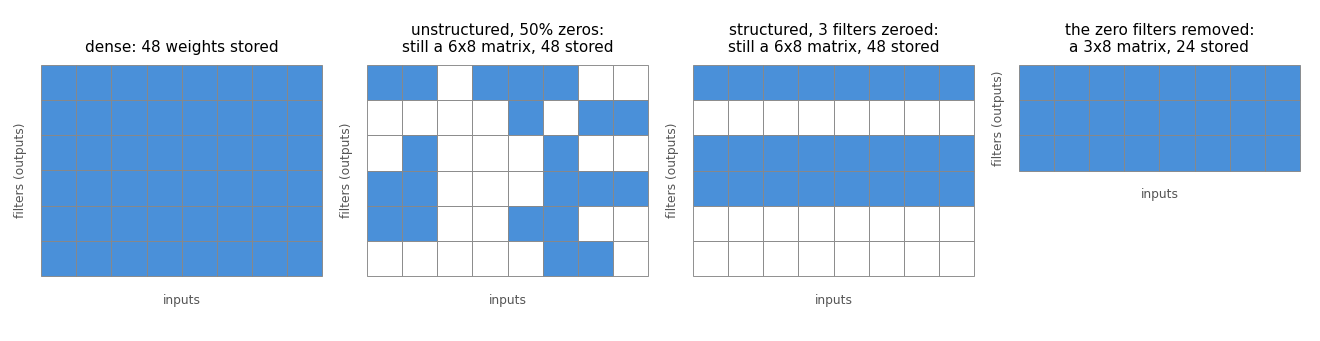

The figure shows the idea on a small weight matrix. Unstructured pruning leaves zeros scattered over a matrix of the old shape. Structured pruning sets whole rows to zero, and a zero row can be deleted, which leaves a smaller, ordinary, dense matrix.

We go through it in the same order as before: one mask by hand, then the PyTorch function, then the step that is new here, deleting the rows.

### 4.1 A structured mask by hand

In Section 2 you ranked single weights by their absolute value. Now the unit is a filter, so we need **one number per filter**. The usual choice is the L2 norm of the filter: the square root of the sum of its squared weights. Filters with a small norm produce small outputs and are the first candidates.

Build the mask for the second convolution and prune half of its filters. The steps mirror Section 2:

- `w.pow(2).sum(dim=(1, 2, 3))` sums the squares over all dimensions except the first, which gives one value per filter,
- the mask must have the shape of `w`, with the same value for all weights of a filter. For a vector `keep` with one entry per filter, `keep.float().view(-1, 1, 1, 1).expand_as(w)` does this: `view` turns the vector into the shape `[32, 1, 1, 1]`, and `expand_as` repeats it over the other dimensions.

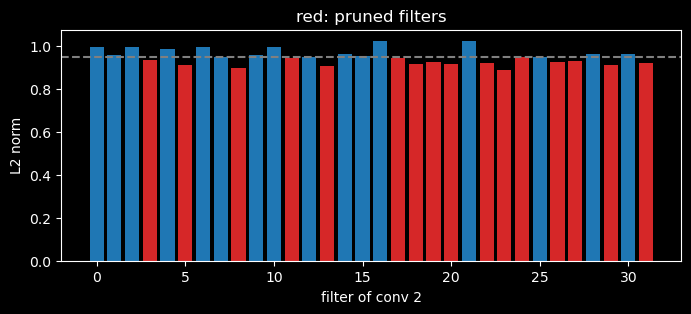

baseline accuracy:                              0.7513
half of the single weights of conv 2 removed:   0.7274   (Section 2)
half of the filters of conv 2 removed:          0.2921


In [19]:
model = load_fp()
w = model.features[4].weight.detach()        # second convolution, shape [32, 16, 3, 3]
amount = 0.5

# TODO (student): 1. norms:     the L2 norm of every filter (a vector with 32 entries)
#                 2. k:         how many filters have to be pruned
#                 3. threshold: the k-th smallest norm
#                 4. keep:      a boolean vector, True for the filters whose norm is above the threshold
#                 5. mask_s:    a tensor of the shape of w, 1.0 for all weights of the kept filters, 0.0 for the rest
norms = w.pow(2).sum(dim=(1, 2, 3)).sqrt()
k = int(amount * norms.numel())
threshold = norms.kthvalue(k).values
keep = norms > threshold
mask_s = keep.float().view(-1, 1, 1, 1).expand_as(w)

assert mask_s.shape == w.shape and int(keep.sum()) == 16
assert (w * mask_s).abs().sum(dim=(1, 2, 3)).eq(0).sum() == 16, "Exactly 16 filters should be entirely zero."

plt.figure(figsize=(8, 3))
plt.bar(range(len(norms)), norms.tolist(), color=["tab:blue" if kept else "tab:red" for kept in keep.tolist()])
plt.axhline(threshold.item(), color="gray", linestyle="--")
plt.xlabel("filter of conv 2")
plt.ylabel("L2 norm")
plt.title("red: pruned filters")
plt.show()

with torch.no_grad():
    model.features[4].weight.copy_(w * mask_s)
conv2_structured_acc = evaluate(model, test_loader)
print(f"baseline accuracy:                              {base_acc:.4f}")
print(f"half of the single weights of conv 2 removed:   {conv2_unstructured_acc:.4f}   (Section 2)")
print(f"half of the filters of conv 2 removed:          {conv2_structured_acc:.4f}")

Both prunings removed half of the weights of the same layer, and the results are far apart. A filter with a small norm still contains some useful weights, and they are removed together with the useless ones. Unstructured pruning could pick the least important weights one by one, wherever they were. This is the price of structure. Section 4.3 shows what it buys.

### 4.2 The same thing with `torch.nn.utils.prune`

`prune.ln_structured` builds this mask for you:

```
prune.ln_structured(layer, name="weight", amount=0.5, n=2, dim=0)
```

- `dim=0` says that the groups are the slices along dimension 0 of the weight. The weight of a convolution has the shape `[out, in, k, k]`, so these are the filters.
- `n=2` is the criterion: the groups are ranked by their L2 norm.
- `amount=0.5` prunes half of the groups.

As in Section 3.1 the result is a `weight_orig` and a `weight_mask`. First check that the function reproduces your mask, then prune 25% of the filters of **every** convolution. The linear layer is left alone here: its rows are the ten classes, and none of them can be removed.

In [ ]:
model = load_fp()
conv2 = model.features[4]
# TODO (student): prune half of the filters of conv2 with prune.ln_structured

print("same mask as the one you built by hand:", torch.equal(conv2.weight_mask, mask_s))

model_s = load_fp()
for conv in conv_layers(model_s):
    # TODO (student): prune 25% of the filters of conv by their L2 norm


masked_acc = evaluate(model_s, test_loader)
print(f"\nsparsity of the model: {sparsity(model_s):.3f}")
print(f"accuracy, 25% of the filters of every convolution pruned:   {masked_acc:.4f}")
print(f"accuracy, 25% of the single weights of every layer pruned:  {one_shot_acc['L1 (magnitude)'][AMOUNTS.index(0.25)]:.4f}   (Section 3.2)")
print(f"baseline:                                                   {base_acc:.4f}")

The comparison from the previous cell repeats on the whole network: at the same amount, structured pruning costs far more accuracy than unstructured pruning.

> **Question.** Why is the sparsity of the model lower than 25%, although a quarter of the filters of every convolution is gone?

### 4.3 Removing the channels for real

So far nothing was gained. The model is still a set of tensors of the old shape, with a quarter of their filters set to zero. Now comes the step from the last panel of the figure at the beginning of this section: the zero filters are deleted. The result is an ordinary, dense, smaller network that runs on any hardware.

A filter does not live alone, though. Removing output channel `c` of a convolution means removing:

- filter `c` of that convolution and its bias,
- entry `c` of the following batch norm (weight, bias and both running statistics),
- input channel `c` of the **next** layer, because the feature map it was reading no longer exists.

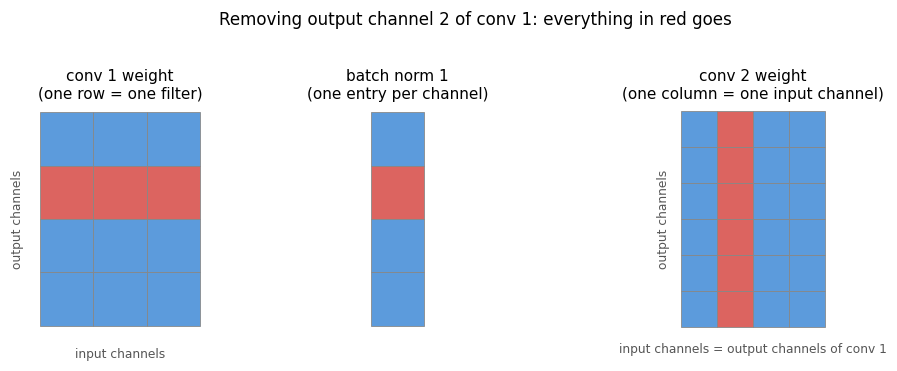

`shrink` below builds a new, smaller `SmallCNN` and copies the surviving parameters into it. Complete the two marked places. Indexing with a boolean vector keeps the entries where the vector is `True`: `w[keep]` selects along the first dimension (the filters), and `w[:, prev]` along the second (the input channels).

In [21]:
def kept_channels(conv):
    # A boolean vector with one entry per filter: True if the filter is not entirely zero
    # TODO (student): use conv.weight.detach() and sum the absolute values over dimensions (1, 2, 3)
    return conv.weight.detach().abs().sum(dim=(1, 2, 3)) > 0


def shrink(model):
    # Returns a new, smaller SmallCNN without the channels whose filters are entirely zero
    convs = [model.features[i] for i in (0, 4, 8)]
    bns = [model.features[i] for i in (1, 5, 9)]
    linear = model.classifier[1]

    keeps = [kept_channels(conv) for conv in convs]
    small = SmallCNN(channels=[int(keep.sum()) for keep in keeps]).to(device)
    new_convs = [small.features[i] for i in (0, 4, 8)]
    new_bns = [small.features[i] for i in (1, 5, 9)]

    prev = torch.ones(3, dtype=torch.bool, device=device)      # the 3 input channels of the image are all kept
    with torch.no_grad():
        for conv, bn, new_conv, new_bn, keep in zip(convs, bns, new_convs, new_bns, keeps):
            # TODO (student): copy into new_conv.weight the weights of conv, keeping only
            #                 the filters in `keep` and the input channels in `prev`
            new_conv.weight.copy_(conv.weight[keep][:, prev])

            new_conv.bias.copy_(conv.bias[keep])
            for name in ["weight", "bias", "running_mean", "running_var"]:
                getattr(new_bn, name).copy_(getattr(bn, name)[keep])
            prev = keep

        # The linear layer reads (channels of conv 3) x (4 x 4 positions) inputs.
        # Reshape its weight so that the channels are a dimension of their own, then select.
        w = linear.weight.view(10, len(prev), 16)[:, prev]
        small.classifier[1].weight.copy_(w.reshape(10, -1))
        small.classifier[1].bias.copy_(linear.bias)
    return small.eval()


small_25 = shrink(model_s)
print(small_25.features)
print(f"\nparameters: {count_parameters(load_fp())} -> {count_parameters(small_25)}")
print(f"accuracy with masks:           {masked_acc:.4f}")
print(f"accuracy of the shrunk model:  {evaluate(small_25, test_loader):.4f}")
assert [c.out_channels for c in conv_layers(small_25)] == [12, 24, 48]

Sequential(
  (0): Conv2d(3, 12, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(12, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(12, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(24, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (10): ReLU()
  (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)

parameters: 34058 -> 21226
accuracy with masks:           0.2572
accuracy of the shrunk model:  0.2691


The network is now really smaller: 12, 24 and 48 channels in place of 16, 32 and 64.

The two accuracies are not the same. In the masked model a pruned filter still has its bias and its batch norm, so its channel carries a constant value into the next layer. In the shrunk model the channel is gone completely. The shrunk model is the real pruned network, and it is the one we continue with.

### 4.4 What did we save this time?

`model_stats` collects four numbers for a `SmallCNN` of any size:

- the number of **parameters** and the size of the weights in **flash** (float32),
- the largest activation tensor, which decides the **RAM** (float32),
- the number of **multiplications** for one image, from `layer_costs` of Section 3.3.

Complete the largest activation tensor. The output of a convolution has one value for every output channel at every position of the feature map.

In [22]:
def model_stats(model):
    size = 32                           # height and width of the feature map, 32 for the input image
    largest = 3 * size * size           # the input image itself
    for layer in model.features:
        if isinstance(layer, nn.Conv2d):
            # TODO (student): if the output of this convolution has more values than `largest`, update `largest`
            output_size = layer.out_channels * size * size
            if output_size > largest:
                largest = output_size
        elif isinstance(layer, nn.MaxPool2d):
            size //= 2
    params = count_parameters(model)
    mults = sum(c["mults"] for c in layer_costs(model))
    return {"params": params, "flash_kb": params * 4 / 1024, "ram_kb": largest * 4 / 1024, "mults": mults}


def latency_ms(model, batch=256, repeats=5):
    # Time for one batch on the CPU, the best of a few runs
    model.to("cpu").eval()
    x = torch.randn(batch, 3, 32, 32)
    times = []
    with torch.no_grad():
        model(x)
        for _ in range(repeats):
            start = time.perf_counter()
            model(x)
            times.append(time.perf_counter() - start)
    model.to(device)
    return min(times) * 1000


def structured_prune(amount):
    # A fresh model with `amount` of the filters of every convolution pruned and removed
    model = load_fp()
    for conv in conv_layers(model):
        prune.ln_structured(conv, name="weight", amount=amount, n=2, dim=0)
    return shrink(model)


small_50 = structured_prune(0.5)
assert model_stats(load_fp())["ram_kb"] == 64.0 and model_stats(small_50)["ram_kb"] == 32.0

rows = [("dense", load_fp()), ("unstructured 50%", model_l1), ("structured 25%", small_25), ("structured 50%", small_50)]
print(f"{'model':<20}{'parameters':>11}{'flash [KB]':>12}{'RAM [KB]':>10}{'mult. [M]':>11}{'CPU [ms]':>10}")
for name, m in rows:
    s = model_stats(m)
    print(f"{name:<20}{s['params']:>11}{s['flash_kb']:>12.1f}{s['ram_kb']:>10.1f}{s['mults'] / 1e6:>11.2f}{latency_ms(m):>10.1f}")

print(f"\n{'':<8}{'weights':>18}{'multiplications':>30}")
print(f"{'layer':<8}{'dense':>9}{'struct. 50%':>13}{'dense':>14}{'struct. 50%':>13}")
for d, p in zip(layer_costs(load_fp()), layer_costs(small_50)):
    print(f"{d['name']:<8}{d['weights']:>9}{p['weights']:>13}{d['mults']:>14}{p['mults']:>13}")

model                parameters  flash [KB]  RAM [KB]  mult. [M]  CPU [ms]
dense                     34058       133.0      64.0       2.81      24.3
unstructured 50%          34058       133.0      64.0       2.81      23.6
structured 25%            21226        82.9      48.0       1.67      18.8
structured 50%            11274        44.0      32.0       0.82      15.8

                   weights               multiplications
layer       dense  struct. 50%         dense  struct. 50%
conv 1        432          216        442368       221184
conv 2       4608         1152       1179648       294912
conv 3      18432         4608       1179648       294912
linear      10240         5120         10240         5120


This is the central result of the laboratory. Unstructured pruning changed none of the columns. Structured pruning reduced all of them: flash, RAM, the amount of computation and the measured time, without any special hardware or library.

The second table shows where the savings come from. Look at the linear layer. It was never pruned itself, and it still lost half of its weights, because its inputs are the channels of the last convolution. This is how the fully connected part of a network gets smaller for real: by removing the features it reads. In a network with hidden linear layers the same rule applies to neurons: removing a neuron deletes one row of its own weight matrix and one column in the next layer.

> **Question.** Half of the channels were removed, but far more than half of the parameters and multiplications disappeared. Why? Two layers lost only a half of their weights. Which ones, and why?

> **Question.** After the pruning, which layer holds the largest share of the weights? Connect this with Section 3.3: what would you prune next?

### 4.5 Fine-tuning the small networks

The shrunk networks lost a lot of accuracy, exactly as the masked one did. They are ordinary networks, so they can be fine-tuned with the plain `train`, and they train faster than the original. We keep the results in `pruned_models` for Section 6.

In [23]:
FT_EPOCHS = 2
pruned_models = {0.0: load_fp(), 0.25: small_25, 0.5: small_50}
pruned_acc = {0.0: base_acc}

for amount in [0.25, 0.5]:
    print(f"--- structured {int(amount * 100)}%: accuracy before fine-tuning {evaluate(pruned_models[amount], test_loader):.4f} ---")
    torch.manual_seed(3)
    # TODO (student): fine-tune pruned_models[amount] for FT_EPOCHS epochs
    pruned_models[amount].to(device)
    train(pruned_models[amount], epochs=FT_EPOCHS)

    pruned_acc[amount] = evaluate(pruned_models[amount], test_loader)

print(f"\n{'channels pruned':<18}{'parameters':>11}{'accuracy':>10}")
for amount, m in pruned_models.items():
    print(f"{str(int(amount * 100)) + '%':<18}{count_parameters(m):>11}{pruned_acc[amount]:>10.4f}")

--- structured 25%: accuracy before fine-tuning 0.2691 ---
epoch 1/2  last batch loss: 0.679  test accuracy: 0.693
epoch 2/2  last batch loss: 0.780  test accuracy: 0.720
--- structured 50%: accuracy before fine-tuning 0.1022 ---
epoch 1/2  last batch loss: 1.126  test accuracy: 0.635
epoch 2/2  last batch loss: 1.141  test accuracy: 0.653

channels pruned    parameters  accuracy
0%                      34058    0.7513
25%                     21226    0.7197
50%                     11274    0.6533


> **Question.** Compare with Section 3.2: unstructured pruning of 50% of the weights cost almost nothing after fine-tuning. Structured pruning of 50% of the channels costs more. Which of the two would you deploy on a microcontroller, and why?

## 5. Iterative pruning

So far we pruned once and fine-tuned afterwards (**one-shot** pruning). The alternative is to do it in small steps:

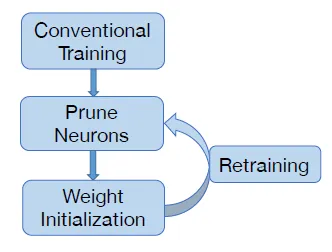

1. prune a part of the remaining weights,
2. fine-tune for a short time,
3. repeat until the target sparsity is reached.

The idea is that the network never has to recover from a large shock. After each small step the remaining weights adapt, and the next step is decided on weights that already reflect the previous one.

Calling a pruning function on a layer that is already pruned prunes it further: `amount` then refers to the weights that are **still there**, and PyTorch combines the masks.

> **Question (answer before running).** Five rounds, each pruning 37% of the remaining weights. What is the sparsity at the end?

Complete `prune_and_finetune`. We use unstructured magnitude pruning on all prunable layers, as in Section 3.

In [ ]:
def prune_and_finetune(model, amount, epochs=1):
    # One round of iterative pruning. Returns (sparsity, accuracy before fine-tuning, accuracy after fine-tuning).
    # TODO (student): 1. prune every prunable layer by `amount` with prune.l1_unstructured
    #                 2. evaluate the model
    #                 3. fine-tune it for `epochs` epochs
    #                 4. evaluate it again

    return sparsity(model), acc_before, acc_after


ROUNDS = 5
STEP = 0.37

torch.manual_seed(4)
model_it = load_fp()
history = [(0.0, base_acc, base_acc)]
for r in range(ROUNDS):
    history.append(prune_and_finetune(model_it, STEP))
    print(f"round {r + 1}: sparsity {history[-1][0]:.3f}  before fine-tuning {history[-1][1]:.4f}  after {history[-1][2]:.4f}\n")

For a fair comparison, the one-shot model gets the same final sparsity and the same total number of fine-tuning epochs.

In [ ]:
final_sparsity = history[-1][0]

torch.manual_seed(4)
model_os = load_fp()
one_shot = prune_and_finetune(model_os, final_sparsity, epochs=ROUNDS)

sp = [h[0] for h in history]
plt.figure(figsize=(8, 4))
plt.plot(sp, [h[2] for h in history], "o-", label="iterative, after fine-tuning")
plt.plot(sp[1:], [h[1] for h in history[1:]], "x:", color="tab:blue", label="iterative, right after pruning")
plt.plot([one_shot[0]], [one_shot[2]], "s", color="tab:red", markersize=9, label=f"one-shot, {ROUNDS} epochs of fine-tuning")
plt.axhline(base_acc, color="gray", linestyle="--", label="baseline")
plt.xlabel("sparsity")
plt.ylabel("test accuracy")
plt.legend()
plt.grid()
plt.show()

print(f"iterative: sparsity {history[-1][0]:.3f}, accuracy {history[-1][2]:.4f}")
print(f"one-shot:  sparsity {one_shot[0]:.3f}, accuracy {one_shot[2]:.4f}")

The dotted line shows what every pruning step does to the network before it is repaired: the accuracy drops sharply each time, and one epoch of fine-tuning brings most of it back. The solid line is the trade-off curve of this network. Up to a sparsity of about 60% it stays at the level of the baseline, after that every further step costs accuracy.

At the same final sparsity and with the same number of fine-tuning epochs, the iterative model usually ends above the one-shot model. The gap grows with the sparsity: at moderate sparsity the two are practically equal, because a single step is not a large shock yet.

Iterative pruning has a second, practical advantage. One run gives the whole curve, so you can stop at the point that your accuracy budget allows, without deciding the sparsity in advance.

> **Question.** The first rounds end slightly *above* the baseline. Pruning did not add information to the network. Where does the improvement come from?

## 6. Pruning and quantization together

We now have two ways of making a model smaller: fewer bits per weight (Laboratory 2) and fewer weights (structured pruning, Section 4). They can be combined, and the question is which combinations are worth it.

With two goals, small size and high accuracy, there is no single best model. A model is **dominated** if another model is at least as small *and* at least as accurate, and better in one of the two. The models that are not dominated by any other form the **Pareto front**. Those are the only ones worth considering, and which of them to deploy depends on the device.

### 6.1 Quantization tools from Laboratory 2

The next cell contains the reference solution of Laboratory 2 in compact form: fake quantization with the straight-through estimator, batch norm folding, `QuantSmallCNN` and `calibrate`. There is nothing to complete, run it.

In [ ]:
def qrange(bits, signed):
    return (-(2 ** (bits - 1)), 2 ** (bits - 1) - 1) if signed else (0, 2 ** bits - 1)


def compute_qparams(r_min, r_max, bits, signed=False):
    qmin, qmax = qrange(bits, signed)
    r_min = torch.clamp(torch.as_tensor(r_min, dtype=torch.float32), max=0.0)
    r_max = torch.clamp(torch.as_tensor(r_max, dtype=torch.float32), min=0.0)
    scale = torch.clamp((r_max - r_min) / (qmax - qmin), min=1e-8)
    return scale, torch.clamp(torch.round(qmin - r_min / scale), qmin, qmax)


def fake_quantize(r, scale, zero_point, qmin, qmax):
    x = r / scale
    x = x + (torch.round(x) - x).detach()                      # straight-through estimator
    return (torch.clamp(x + zero_point, qmin, qmax) - zero_point) * scale


def quantize_weight(w, bits):
    # symmetric, signed, one scale per output channel
    qmin, qmax = qrange(bits, signed=True)
    with torch.no_grad():
        max_abs = w.abs().amax(dim=tuple(range(1, w.dim())), keepdim=True)
        scale = torch.clamp(max_abs / qmax, min=1e-8)
    return fake_quantize(w, scale, 0.0, qmin, qmax)


class ActQuantizer(nn.Module):
    def __init__(self, bits, signed=False, momentum=0.9):
        super().__init__()
        self.bits, self.signed, self.momentum, self.enabled = bits, signed, momentum, True
        self.register_buffer("min_val", torch.tensor(0.0))
        self.register_buffer("max_val", torch.tensor(0.0))
        self.register_buffer("initialized", torch.tensor(False))

    def forward(self, x):
        if self.training:
            with torch.no_grad():
                if not self.initialized:
                    self.min_val.copy_(x.min())
                    self.max_val.copy_(x.max())
                    self.initialized.fill_(True)
                else:
                    self.min_val.copy_(self.momentum * self.min_val + (1 - self.momentum) * x.min())
                    self.max_val.copy_(self.momentum * self.max_val + (1 - self.momentum) * x.max())
        if not self.enabled:
            return x
        scale, zero_point = compute_qparams(self.min_val, self.max_val, self.bits, self.signed)
        return fake_quantize(x, scale, zero_point, *qrange(self.bits, self.signed))


class QuantConv2d(nn.Module):
    def __init__(self, conv, bits):
        super().__init__()
        self.conv, self.bits = copy.deepcopy(conv), bits

    def forward(self, x):
        return F.conv2d(x, quantize_weight(self.conv.weight, self.bits), self.conv.bias, self.conv.stride, self.conv.padding)


class QuantLinear(nn.Module):
    def __init__(self, linear, bits):
        super().__init__()
        self.linear, self.bits = copy.deepcopy(linear), bits

    def forward(self, x):
        return F.linear(x, quantize_weight(self.linear.weight, self.bits), self.linear.bias)


def fold_model(model):
    # A copy of the model with every batch norm folded into the convolution in front of it
    folded = copy.deepcopy(model).cpu().eval()
    layers = list(folded.features)
    for i in range(len(layers) - 1):
        if isinstance(layers[i], nn.Conv2d) and isinstance(layers[i + 1], nn.BatchNorm2d):
            conv, bn = layers[i], layers[i + 1]
            factor = bn.weight / torch.sqrt(bn.running_var + bn.eps)
            new = nn.Conv2d(conv.in_channels, conv.out_channels, conv.kernel_size, padding=conv.padding)
            with torch.no_grad():
                new.weight.copy_(conv.weight * factor.view(-1, 1, 1, 1))
                new.bias.copy_((conv.bias - bn.running_mean) * factor + bn.bias)
            layers[i], layers[i + 1] = new, nn.Identity()
    folded.features = nn.Sequential(*layers)
    return folded.to(device)


class QuantSmallCNN(nn.Module):
    # A folded SmallCNN (of any size) with fake-quantized weights and activations
    def __init__(self, folded, w_bits, a_bits):
        super().__init__()
        self.input_quant = ActQuantizer(8, signed=True)
        layers = []
        for layer in folded.features:
            if isinstance(layer, nn.Conv2d):
                layers.append(QuantConv2d(layer, w_bits))
            elif isinstance(layer, nn.ReLU):
                layers += [nn.ReLU(), ActQuantizer(a_bits)]
            elif isinstance(layer, nn.MaxPool2d):
                layers.append(nn.MaxPool2d(2))
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(nn.Flatten(), QuantLinear(folded.classifier[1], w_bits))

    def forward(self, x):
        return self.classifier(self.features(self.input_quant(x)))


def calibrate(model, loader, num_batches=8):
    model.to(device).train()
    for m in model.modules():
        if isinstance(m, ActQuantizer):
            m.enabled = False
    with torch.no_grad():
        for i, (images, _) in enumerate(loader):
            if i >= num_batches:
                break
            model(images.to(device))
    for m in model.modules():
        if isinstance(m, ActQuantizer):
            m.enabled = True
    model.eval()


# A quick check on the dense model: 8-bit PTQ should match the float accuracy
check = QuantSmallCNN(fold_model(load_fp()), w_bits=8, a_bits=8)
calibrate(check, train_loader)
print(f"float: {base_acc:.4f}   8-bit PTQ: {evaluate(check, test_loader):.4f}")

### 6.2 The experiment

We already have three float models from Section 4.5: the dense one, and the ones with 25% and 50% of the channels removed, both fine-tuned. Each of them is now quantized to 8 and to 4 bits with a short QAT, as in Laboratory 2 (fold, quantize, calibrate, train with a small learning rate). Together with the three float models this gives nine points.

For every point we record the accuracy and two sizes:

- **flash**: the weights with `bits` bits each, and the biases with 32 bits each, as in Laboratory 2,
- **RAM**: the largest activation tensor, with `bits` bits per value.

Complete `flash_kb`. The cell trains six small models for two epochs each, so it takes a few minutes.

In [ ]:
def flash_kb(model, bits):
    # TODO (student): weights of all prunable layers with `bits` bits each, biases with 32 bits each, in KB



QAT_EPOCHS = 2
QAT_LR = 1e-4
QUANT_BITS = [8, 4]

points = []
for amount, float_model in pruned_models.items():
    folded = fold_model(float_model)
    ram_values = model_stats(float_model)["ram_kb"] * 1024 / 4          # number of values in the largest activation
    label = f"P{int(amount * 100)}"
    points.append({"label": f"{label} float", "prune": amount, "bits": 32,
                   "flash": flash_kb(folded, 32), "ram": ram_values * 32 / 8 / 1024, "acc": pruned_acc[amount]})
    for bits in QUANT_BITS:
        print(f"--- {int(amount * 100)}% of the channels pruned, {bits} bits ---")
        torch.manual_seed(5)
        qat = QuantSmallCNN(folded, w_bits=bits, a_bits=bits)
        calibrate(qat, train_loader)
        train(qat, epochs=QAT_EPOCHS, lr=QAT_LR)
        points.append({"label": f"{label} {bits}b", "prune": amount, "bits": bits,
                       "flash": flash_kb(folded, bits), "ram": ram_values * bits / 8 / 1024, "acc": evaluate(qat, test_loader)})

assert abs(flash_kb(fold_model(load_fp()), 32) - 132.2) < 0.1

### 6.3 The Pareto front

Write `pareto_front`. A point is on the front if no other point dominates it. Use the definition from the beginning of this section, with `flash` as the size.

In [ ]:
def pareto_front(points, cost="flash"):
    # Returns the points that are not dominated by any other point, sorted by the given cost
    front = []
    for p in points:
        # TODO (student): dominated = True if some other point q is at least as cheap and at least as accurate
        #                 as p, and strictly better in at least one of the two (the cost is p[cost])
        # dominated = 
        if not dominated:
            front.append(p)
    return sorted(front, key=lambda p: p[cost])


# The number of multiplications depends only on the architecture, not on the number of bits
for p in points:
    p["mults"] = model_stats(pruned_models[p["prune"]])["mults"] / 1e6

front_flash = pareto_front(points, "flash")
front_mults = pareto_front(points, "mults")

print(f"{'model':<12}{'flash [KB]':>11}{'RAM [KB]':>10}{'mult. [M]':>11}{'accuracy':>10}{'front: flash':>14}{'front: mult.':>14}")
for p in sorted(points, key=lambda p: p["flash"]):
    print(f"{p['label']:<12}{p['flash']:>11.1f}{p['ram']:>10.1f}{p['mults']:>11.2f}{p['acc']:>10.4f}"
          f"{'yes' if p in front_flash else '':>14}{'yes' if p in front_mults else '':>14}")

colors = {32: "tab:gray", 8: "tab:blue", 4: "tab:orange"}
markers = {0.0: "o", 0.25: "s", 0.5: "^"}

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, cost, front in [(axes[0], "flash", front_flash), (axes[1], "mults", front_mults)]:
    for p in points:
        ax.scatter(p[cost], p["acc"], color=colors[p["bits"]], marker=markers[p["prune"]], s=90, zorder=3)
        # on the right plot the three bit widths share one x position, so the 4-bit labels go to the left
        left = cost == "mults" and p["bits"] == 4
        ax.annotate(p["label"], (p[cost], p["acc"]), textcoords="offset points", fontsize=8,
                    xytext=(-8, -3) if left else (8, 4), ha="right" if left else "left")
    ax.plot([p[cost] for p in front], [p["acc"] for p in front], color="tab:green", linewidth=2, label="Pareto front", zorder=2)
    ax.grid(which="both", alpha=0.4)

axes[0].axvline(32, color="red", linestyle=":", label="Arduino Uno flash (32 KB)")
axes[0].set_xscale("log")
axes[0].set_xlabel("flash for the weights [KB], logarithmic")
axes[0].set_ylabel("test accuracy")
axes[0].set_title("accuracy against memory")
axes[0].legend()

axes[1].set_xlim(0, 3.2)
axes[1].set_xlabel("multiplications for one image [millions]")
axes[1].set_title("accuracy against computation")
axes[1].legend()
plt.show()

In the labels, `P25 8b` means 25% of the channels pruned and 8 bits. The colour is the number of bits, the shape of the marker is the amount of pruning.

> **Question.** Which models are dominated, and by which ones? Starting from the float model, which of the two levers would you pull first to get below 32 KB, and which one after that?

> **Question.** Which of the two techniques reduces RAM, and why does unstructured pruning not appear in this table at all?

> **Question.** Why in those two tables different models are on the Pareto front?


Every model here was trained once and only for a few epochs, so small differences are noise. 

## 7. Wrap-up

### 7.1 Exercises

1. **Global pruning.** In Sections 3 and 5 every layer lost the same fraction of its weights. `prune.global_unstructured(parameters, pruning_method=prune.L1Unstructured, amount=...)` ranks the weights of all layers together, with `parameters = [(layer, "weight") for layer in prunable_layers(model)]`. Repeat the sweep of Section 3.2 with it and print the sparsity of every layer. Which layers are pruned the most, and why?
2. **Iterative structured pruning.** Combine Sections 4 and 5: prune 12.5% of the channels, shrink, fine-tune, and repeat until half of the channels are gone. Is it better than pruning 50% at once?
3. **Other criteria.** Replace the L2 norm in `prune.ln_structured` by `n=1`, and by random selection (`prune.random_structured`). How much does the criterion matter after fine-tuning?
4. **A wider start.** Train `SmallCNN(width=32)`, prune half of its channels and fine-tune. Compare with `SmallCNN(width=16)` trained from scratch: the two have a similar size. Which one is better?
5. **More points.** Add 2-bit and 6-bit models, or a model with 75% of the channels pruned, to the experiment of Section 6. Does the front change?
6. **Pruning neurons.** Give the classifier a hidden layer (`Linear(1024, 64)`, `ReLU`, `Linear(64, 10)`), train the network, and prune half of the 64 neurons with `prune.ln_structured` on the first linear layer. Then remove them for real: which rows and which columns have to go? How much smaller is the model?
7. **Sparse storage.** Estimate the size of the unstructured model of Section 3.2 in a sparse format, where every non-zero weight is stored with 32 bits for its value and 16 bits for its position. From which sparsity on does this pay off?

### 7.2 Summary

- Pruning removes parameters from a trained network. A mask sets them to zero, and fine-tuning lets the rest compensate.
- Which weights are removed matters: magnitude is a simple and effective criterion.
- The layers differ. The linear layer holds much of the memory, little of the computation, and tolerates the most pruning. The early convolutions are the most sensitive.
- Unstructured pruning reaches high sparsity at little cost in accuracy, but the model keeps its shape. Without sparse storage and sparse computation nothing is saved.
- Structured pruning removes whole channels. It costs more accuracy, and the result is a smaller dense network: less flash, less RAM, fewer multiplications, on any hardware.
- Pruning in small steps with fine-tuning in between is gentler than pruning everything at once.
- Pruning and quantization combine. The Pareto front shows which combinations are worth considering.

### 7.4 Further reading

- S. Han, J. Pool, J. Tran, W. Dally, *Learning both Weights and Connections for Efficient Neural Networks*, 2015, arXiv:1506.02626.
- H. Li et al., *Pruning Filters for Efficient ConvNets*, 2016, arXiv:1608.08710.
- J. Frankle, M. Carbin, *The Lottery Ticket Hypothesis: Finding Sparse, Trainable Neural Networks*, 2018, arXiv:1803.03635.
- S. Han, H. Mao, W. Dally, *Deep Compression: Compressing Deep Neural Networks with Pruning, Trained Quantization and Huffman Coding*, 2015, arXiv:1510.00149.
- PyTorch pruning tutorial: https://pytorch.org/tutorials/intermediate/pruning_tutorial.html